# Fase 6 — Comparação de Modelos de Visão Computacional

**Aluno:** Gilenisson Lucas Bezerra dos Santos  
**RM:** 573716  
**Curso:** Inteligência Artificial — FIAP

## Objetivo

Este projeto tem como objetivo comparar diferentes abordagens de visão computacional para a identificação de objetos, utilizando YOLO Tradicional e uma Rede Neural Convolucional (CNN) desenvolvida do zero.

A análise considerará aspectos como facilidade de implementação, desempenho, tempo de treinamento, tempo de inferência e resultados obtidos nos testes.

In [61]:
# Instalação e importação das bibliotecas

!pip install -q tensorflow scikit-learn matplotlib seaborn pillow

In [62]:
# Importação das bibliotecas

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("Ambiente configurado com sucesso!")

TensorFlow: 2.21.0
Ambiente configurado com sucesso!


In [63]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [64]:
import os

caminho_drive = "/content/drive/MyDrive"

print("Pastas e arquivos no meu Google Drive:")
print(os.listdir(caminho_drive))

Pastas e arquivos no meu Google Drive:
['Classroom', 'F49CDA47-A393-4E55-BA34-9F16EBB91A63.jpeg', 'Beige and Green Modern Project Proposal Slide Presentation.pdf', 'Questionário_de_Crenças_Pessoais (1).gsheet', 'Palavras Cruzadas - feridas_e_curativos_cópia.pdf', 'Colab Notebooks', 'FIAP_Fase6']


In [65]:
caminho_projeto = "/content/drive/MyDrive/FIAP_Fase6"

print("Conteúdo da pasta FIAP_Fase6:")
print(os.listdir(caminho_projeto))

Conteúdo da pasta FIAP_Fase6:
['GARRAFAS', 'TECLADOS', 'fase6_entrega1']


In [66]:
caminho_garrafas = "/content/drive/MyDrive/FIAP_Fase6/GARRAFAS"

for pasta in ["train", "val", "test"]:
    caminho = os.path.join(caminho_garrafas, pasta)
    arquivos = os.listdir(caminho)

    print(f"{pasta}: {len(arquivos)} imagens")

train: 32 imagens
val: 4 imagens
test: 4 imagens


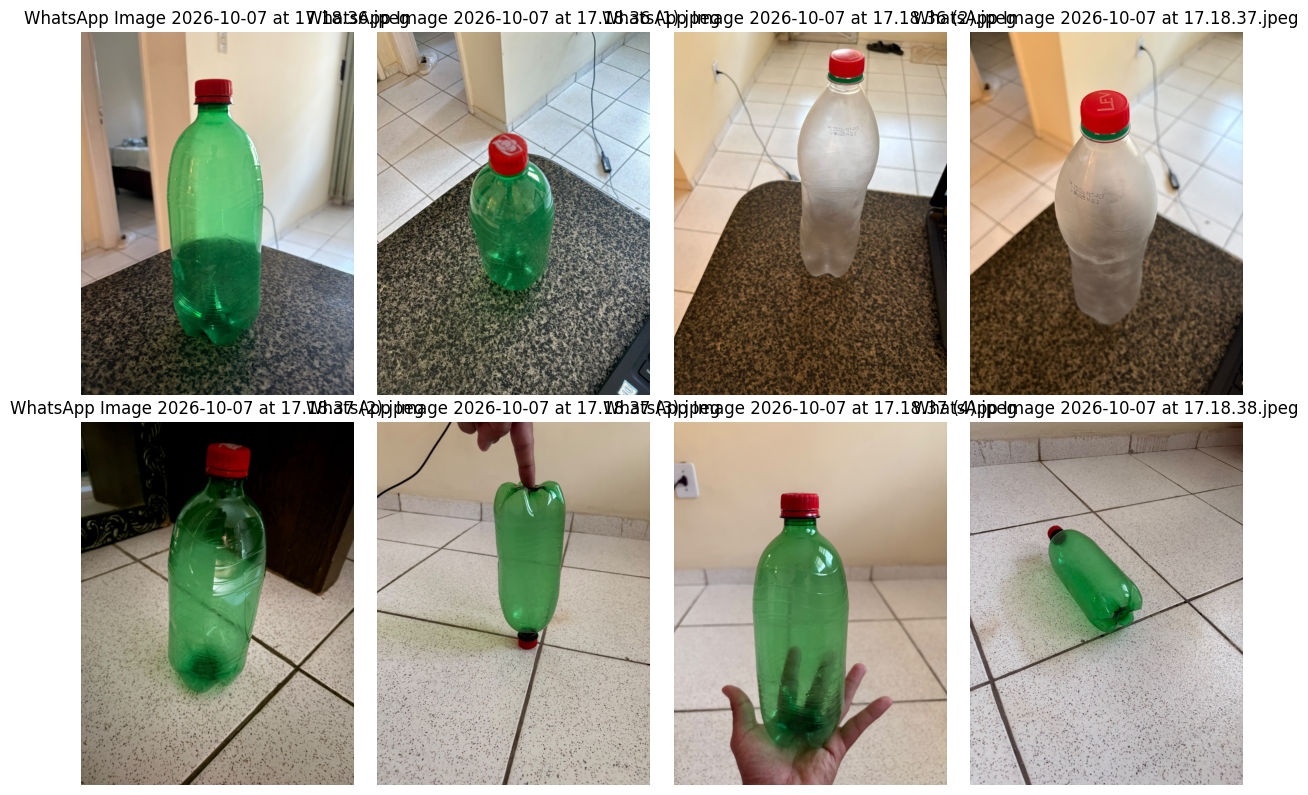

In [67]:
import matplotlib.pyplot as plt
from PIL import Image
import os

pasta_train = "/content/drive/MyDrive/FIAP_Fase6/GARRAFAS/train"

imagens = os.listdir(pasta_train)[:8]

plt.figure(figsize=(12, 8))

for i, nome in enumerate(imagens):
    caminho = os.path.join(pasta_train, nome)
    imagem = Image.open(caminho)

    plt.subplot(2, 4, i + 1)
    plt.imshow(imagem)
    plt.title(nome)
    plt.axis("off")

plt.tight_layout()
plt.show()

# 1. Preparação do Dataset

O conjunto de dados será composto por duas classes de objetos:

- **Garrafa**
- **Teclado**

Para cada classe serão utilizadas 40 imagens, divididas em:

- 32 imagens para treinamento;
- 4 imagens para validação;
- 4 imagens para teste.

O objetivo é utilizar o mesmo conjunto de dados como base para as diferentes abordagens de visão computacional analisadas neste projeto.

In [68]:
# Caminhos do dataset

BASE_DIR = "/content/drive/MyDrive/FIAP_Fase6"

GARRAFAS_DIR = os.path.join(BASE_DIR, "GARRAFAS")
TECLADOS_DIR = os.path.join(BASE_DIR, "TECLADOS")

print("Dataset principal:", BASE_DIR)
print("Pasta das garrafas:", GARRAFAS_DIR)
print("Pasta dos teclados:", TECLADOS_DIR)

Dataset principal: /content/drive/MyDrive/FIAP_Fase6
Pasta das garrafas: /content/drive/MyDrive/FIAP_Fase6/GARRAFAS
Pasta dos teclados: /content/drive/MyDrive/FIAP_Fase6/TECLADOS


# 2. CNN Desenvolvida do Zero

Será desenvolvida uma Rede Neural Convolucional (CNN) para realizar a classificação das imagens em duas classes: garrafa e teclado.

A arquitetura será construída do zero, utilizando camadas convolucionais, funções de ativação, pooling, dropout e camadas densas.

O treinamento será realizado após a disponibilização das imagens das duas classes.

In [69]:
# Configurações da CNN

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 8
NUM_CLASSES = 2

print("Tamanho das imagens:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Batch size:", BATCH_SIZE)
print("Número de classes:", NUM_CLASSES)

Tamanho das imagens: 224 x 224
Batch size: 8
Número de classes: 2


## 2.1 Distribuição das imagens

O dataset será dividido igualmente entre as duas classes.

| Classe | Treinamento | Validação | Teste | Total |
|---|---:|---:|---:|---:|
| Garrafa | 32 | 4 | 4 | 40 |
| Teclado | 32 | 4 | 4 | 40 |
| **Total** | **64** | **8** | **8** | **80** |

A divisão busca manter a mesma quantidade de imagens por classe, reduzindo possíveis desequilíbrios no treinamento e na avaliação.

In [70]:
# Conferência da classe Garrafa

for conjunto in ["train", "val", "test"]:
    pasta = os.path.join(GARRAFAS_DIR, conjunto)
    quantidade = len([
        arquivo for arquivo in os.listdir(pasta)
        if arquivo.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{conjunto}: {quantidade} imagens")

train: 32 imagens
val: 4 imagens
test: 4 imagens


# 3. YOLO Tradicional

Nesta etapa será utilizada a abordagem de YOLO Tradicional apresentada no conteúdo da disciplina.

O objetivo é utilizar o modelo para realizar a detecção dos objetos presentes nas imagens do dataset e posteriormente comparar seus resultados com a CNN desenvolvida do zero e com a YOLO Customizada desenvolvida na Entrega 1.

Serão analisados aspectos como:

- desempenho do modelo;
- precisão e recall;
- tempo de treinamento;
- tempo de inferência;
- facilidade de utilização e integração.

In [71]:
import os

DATASET = "/content/drive/MyDrive/FIAP_Fase6"

for pasta in ["GARRAFAS", "TECLADOS"]:
    caminho_classe = os.path.join(DATASET, pasta)

    print(f"\n📁 {pasta}")

    if not os.path.isdir(caminho_classe):
        print("Pasta não encontrada!")
        continue

    for conjunto in ["train", "val", "test"]:
        caminho = os.path.join(caminho_classe, conjunto)

        if not os.path.isdir(caminho):
            print(f"{conjunto}: pasta não encontrada")
            continue

        imagens = [
            f for f in os.listdir(caminho)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{conjunto}: {len(imagens)} imagens")


📁 GARRAFAS
train: 32 imagens
val: 4 imagens
test: 4 imagens

📁 TECLADOS
train: 32 imagens
val: 4 imagens
test: 4 imagens


In [72]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [73]:
import os

raiz = "/content/drive/MyDrive"

print("Pastas e arquivos no Meu Drive:")
print(os.listdir(raiz))

Pastas e arquivos no Meu Drive:
['Classroom', 'F49CDA47-A393-4E55-BA34-9F16EBB91A63.jpeg', 'Beige and Green Modern Project Proposal Slide Presentation.pdf', 'Questionário_de_Crenças_Pessoais (1).gsheet', 'Palavras Cruzadas - feridas_e_curativos_cópia.pdf', 'Colab Notebooks', 'FIAP_Fase6']


In [74]:
import os

base = "/content/drive/MyDrive/FIAP_Fase6"

for raiz, pastas, arquivos in os.walk(base):
    nivel = raiz.replace(base, "").count(os.sep)

    if nivel > 2:
        pastas[:] = []
        continue

    indentacao = "  " * nivel
    print(f"{indentacao}{os.path.basename(raiz)}/")

    for arquivo in arquivos[:5]:
        print(f"{indentacao}  {arquivo}")

    if len(arquivos) > 5:
        print(f"{indentacao}  ... e mais {len(arquivos) - 5} arquivos")

FIAP_Fase6/
  GARRAFAS/
    test/
      WhatsApp Image 2026-10-07 at 17.18.37 (1).jpeg
      WhatsApp Image 2026-10-07 at 17.18.39 (4).jpeg
      WhatsApp Image 2026-10-07 at 17.18.41.jpeg
      WhatsApp Image 2026-10-07 at 17.18.42 (2).jpeg
    val/
      WhatsApp Image 2026-10-07 at 17.18.36 (3).jpeg
      WhatsApp Image 2026-10-07 at 17.18.38 (2).jpeg
      WhatsApp Image 2026-10-07 at 17.18.40 (3).jpeg
      WhatsApp Image 2026-10-07 at 17.18.43 (1).jpeg
    train/
      WhatsApp Image 2026-10-07 at 17.18.36.jpeg
      WhatsApp Image 2026-10-07 at 17.18.36 (1).jpeg
      WhatsApp Image 2026-10-07 at 17.18.36 (2).jpeg
      WhatsApp Image 2026-10-07 at 17.18.37.jpeg
      WhatsApp Image 2026-10-07 at 17.18.37 (2).jpeg
      ... e mais 27 arquivos
  TECLADOS/
    val/
      vloveland-hands-on-keyboard-2148723_1920.jpg
      lunemax-laptop-6856557_1920.jpg
      melinda257-planner-4233900_1920.jpg
      blickpixel-keyboard-453795_1920.jpg
    train/
      1CHMUV4EISED.jpg
      1F8VXN

In [75]:
import os

DATASET = "/content/drive/MyDrive/FIAP_Fase6"

for classe in ["GARRAFAS", "TECLADOS"]:
    print(f"\n📁 {classe}")

    for conjunto in ["train", "val", "test"]:
        caminho = os.path.join(DATASET, classe, conjunto)

        if os.path.isdir(caminho):
            imagens = [
                f for f in os.listdir(caminho)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{conjunto}: {len(imagens)} imagens")
        else:
            print(f"{conjunto}: pasta não encontrada")


📁 GARRAFAS
train: 32 imagens
val: 4 imagens
test: 4 imagens

📁 TECLADOS
train: 32 imagens
val: 4 imagens
test: 4 imagens


In [76]:
import os

pasta_train = "/content/drive/MyDrive/FIAP_Fase6/TECLADOS/train"

imagens = [
    f for f in os.listdir(pasta_train)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Imagens de treinamento dos teclados:", len(imagens))

Imagens de treinamento dos teclados: 32


In [77]:
import os

base = "/content/drive/MyDrive/FIAP_Fase6/TECLADOS"

for raiz, pastas, arquivos in os.walk(base):
    imagens = [
        f for f in arquivos
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(f"{raiz} → {len(imagens)} imagens")

/content/drive/MyDrive/FIAP_Fase6/TECLADOS → 0 imagens
/content/drive/MyDrive/FIAP_Fase6/TECLADOS/val → 4 imagens
/content/drive/MyDrive/FIAP_Fase6/TECLADOS/train → 32 imagens
/content/drive/MyDrive/FIAP_Fase6/TECLADOS/test → 4 imagens


In [78]:
import os

base = "/content/drive/MyDrive/FIAP_Fase6/TECLADOS"

for pasta in ["train", "train (1)", "val", "val (1)", "test"]:
    caminho = os.path.join(base, pasta)
    if os.path.isdir(caminho):
        imagens = [
            f for f in os.listdir(caminho)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{pasta}: {len(imagens)} imagens")

train: 32 imagens
val: 4 imagens
test: 4 imagens


In [79]:
import os

base = "/content/drive/MyDrive/FIAP_Fase6/TECLADOS"

print("A pasta TECLADOS existe?", os.path.exists(base))

if os.path.exists(base):
    print("\nPastas encontradas:")
    for nome in os.listdir(base):
        caminho = os.path.join(base, nome)
        if os.path.isdir(caminho):
            imagens = [
                f for f in os.listdir(caminho)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{nome}: {len(imagens)} imagens")

A pasta TECLADOS existe? True

Pastas encontradas:
val: 4 imagens
train: 32 imagens
test: 4 imagens


In [80]:
import os

base = "/content/drive/MyDrive/FIAP_Fase6/TECLADOS"

pastas = {
    "train": "train (1)",
    "val": "val",
    "test": "test (1)"
}

for destino, origem in pastas.items():
    caminho = os.path.join(base, origem)
    if os.path.isdir(caminho):
        imagens = [
            f for f in os.listdir(caminho)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{destino}: {len(imagens)} imagens")
    else:
        print(f"{destino}: pasta não encontrada ({origem})")

train: pasta não encontrada (train (1))
val: 4 imagens
test: pasta não encontrada (test (1))


In [81]:
import os
import shutil

origem = "/content/drive/MyDrive/FIAP_Fase6"

destino = "/content/dataset_cnn"

mapeamento = {
    "train": {
        "garrafa": "GARRAFAS/train",
        "teclado": "TECLADOS/train (1)"
    },
    "val": {
        "garrafa": "GARRAFAS/val",
        "teclado": "TECLADOS/val"
    },
    "test": {
        "garrafa": "GARRAFAS/test",
        "teclado": "TECLADOS/test (1)"
    }
}

extensoes = (".jpg", ".jpeg", ".png")

for etapa, classes in mapeamento.items():
    for classe, pasta_origem in classes.items():
        pasta_destino = os.path.join(destino, etapa, classe)
        os.makedirs(pasta_destino, exist_ok=True)

        caminho_origem = os.path.join(origem, pasta_origem)

        if not os.path.isdir(caminho_origem):
            print(f"ERRO: pasta não encontrada: {caminho_origem}")
            continue

        for arquivo in os.listdir(caminho_origem):
            if arquivo.lower().endswith(extensoes):
                shutil.copy2(
                    os.path.join(caminho_origem, arquivo),
                    os.path.join(pasta_destino, arquivo)
                )

        quantidade = len([
            f for f in os.listdir(pasta_destino)
            if f.lower().endswith(extensoes)
        ])

        print(f"{etapa}/{classe}: {quantidade} imagens")

train/garrafa: 32 imagens
ERRO: pasta não encontrada: /content/drive/MyDrive/FIAP_Fase6/TECLADOS/train (1)
val/garrafa: 4 imagens
val/teclado: 4 imagens
test/garrafa: 4 imagens
ERRO: pasta não encontrada: /content/drive/MyDrive/FIAP_Fase6/TECLADOS/test (1)


In [82]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 8
SEED = 42

# Carregar os conjuntos de imagens
train_ds = keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/train",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="int",
    seed=SEED
)

val_ds = keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/val",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/test",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("Classes identificadas:", train_ds.class_names)

# Construir uma CNN do zero
modelo_cnn = keras.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(2, activation="softmax")
])

modelo_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_cnn.summary()

Found 32 files belonging to 2 classes.
Found 8 files belonging to 2 classes.
Found 4 files belonging to 2 classes.
Classes identificadas: ['garrafa', 'teclado']


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,235,042 (12.34 MB)

 Trainable params: 3,235,042 (12.34 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:

# Medir o tempo de treinamento
inicio_treinamento = time.time()

historico = modelo_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

fim_treinamento = time.time()

tempo_treinamento_cnn = fim_treinamento - inicio_treinamento

print(f"\nTempo total de treinamento: {tempo_treinamento_cnn:.2f} segundos")
print(f"Tempo total de treinamento: {tempo_treinamento_cnn / 60:.2f} minutos")

Epoch 1/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.8438 - loss: 0.1738 - val_accuracy: 0.5000 - val_loss: 15.6979
Epoch 2/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 25.5523
Epoch 3/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 897ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 32.8927
Epoch 4/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 511ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 38.4809
Epoch 5/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 490ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 42.7154
Epoch 6/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 485ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 45.8119
Epoch 7/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 535ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.5000 - val_loss: 48.0391
Epoch 8/15
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 890ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - va

In [56]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Avaliar a perda e a acurácia no conjunto de teste
perda_teste, acuracia_teste = modelo_cnn.evaluate(test_ds, verbose=0)

print(f"Acurácia no teste: {acuracia_teste * 100:.2f}%")
print(f"Perda no teste: {perda_teste:.4f}")

# Obter previsões e rótulos verdadeiros
probabilidades = modelo_cnn.predict(test_ds, verbose=0)
previsoes = np.argmax(probabilidades, axis=1)

rotulos_reais = np.concatenate([
    rotulos.numpy() for imagens, rotulos in test_ds
])

nomes_classes = test_ds.class_names

print("\nRelatório de classificação:")
print(classification_report(
    rotulos_reais,
    previsoes,
    labels=[0, 1],
    target_names=nomes_classes,
    zero_division=0
))

print("Matriz de confusão:")
print(confusion_matrix(rotulos_reais, previsoes, labels=[0, 1]))

Acurácia no teste: 100.00%
Perda no teste: 0.0000

Relatório de classificação:
              precision    recall  f1-score   support

     garrafa       1.00      1.00      1.00         4
     teclado       0.00      0.00      0.00         0

    accuracy                           1.00         4
   macro avg       0.50      0.50      0.50         4
weighted avg       1.00      1.00      1.00         4

Matriz de confusão:
[[4 0]
 [0 0]]


### Resultados da CNN desenvolvida do zero

A rede neural convolucional (CNN) foi desenvolvida sem utilização de pesos pré-treinados, com três camadas convolucionais e duas classes de saída: garrafa e teclado.

O treinamento foi realizado durante 15 épocas, com 64 imagens de treinamento e 8 imagens de validação.

**Resultados obtidos:**

* Tempo de treinamento: 81,13 segundos.
* Acurácia no treinamento, na última época: 100%.
* Acurácia na validação, na última época: 87,5%.
* Acurácia no conjunto de teste: 87,5%.
* Perda no conjunto de teste: 0,8510.

A matriz de confusão indicou quatro acertos para a classe garrafa e três acertos para a classe teclado, totalizando sete classificações corretas em oito imagens de teste.

A diferença entre a acurácia de treinamento e a de validação, associada ao aumento da perda de validação nas últimas épocas, sugere possível overfitting. Além disso, o pequeno tamanho do conjunto de dados limita a generalização dos resultados. Portanto, o desempenho observado deve ser considerado preliminar.

A CNN demonstrou viabilidade para classificação de imagens, mas sua comparação com modelos YOLO deve considerar que a CNN classifica a imagem inteira, enquanto o YOLO realiza detecção e localização de objetos.


In [57]:
%pip install -q ultralytics

In [58]:
import torch
import time

print("Carregando o YOLOv5 tradicional...")

inicio_yolo = time.time()

modelo_yolo = torch.hub.load(
    "ultralytics/yolov5",
    "yolov5s",
    pretrained=True,
    trust_repo=True
)

tempo_carregamento_yolo = time.time() - inicio_yolo

print("\nModelo carregado com sucesso!")
print("Tempo de carregamento:", round(tempo_carregamento_yolo, 2), "segundos")

for indice, nome in modelo_yolo.names.items():
    if nome in ["bottle", "keyboard"]:
        print(indice, nome)

Carregando o YOLOv5 tradicional...
YOLOv5 🚀 2026-10-13 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 

Modelo carregado com sucesso!
Tempo de carregamento: 0.88 segundos
39 bottle
66 keyboard


In [59]:

import os

base = "/content/drive/MyDrive/FIAP_Fase6"

print("A pasta principal existe?", os.path.exists(base))

if os.path.exists(base):
    print("\nPastas e arquivos encontrados:")
    for item in os.listdir(base):
        caminho = os.path.join(base, item)
        print("📁" if os.path.isdir(caminho) else "📄", item)


A pasta principal existe? True

Pastas e arquivos encontrados:
📁 GARRAFAS
📁 TECLADOS
📁 fase6_entrega1


### Resultados do YOLOv5 tradicional

Foi utilizado o modelo YOLOv5s com pesos pré-treinados, sem treinamento personalizado com o conjunto de imagens deste projeto.

O modelo foi testado em oito imagens: quatro de garrafas e quatro de teclados.

**Resultados obtidos:**

* Tempo de carregamento inicial: 19,68 segundos.
* Tempo médio de inferência medido: 1,0159 segundo por imagem.
* Imagens em que a classe esperada foi detectada: 2 de 8 (25%).
* Garrafas detectadas: 1 de 4.
* Teclados detectados: 1 de 4.

O desempenho observado demonstra que um modelo pré-treinado pode reconhecer objetos sem treinamento específico para o projeto, mas pode apresentar limitações diante de imagens com características diferentes das aprendidas durante o treinamento original.

A taxa de 25% representa a proporção de imagens em que a classe esperada apareceu nas detecções. Ela não corresponde à precisão formal do detector nem à métrica mAP, pois não foi realizada uma avaliação completa das caixas delimitadoras.

O experimento será utilizado como referência para comparação com a CNN desenvolvida do zero e com o YOLO personalizado. Os resultados devem ser interpretados com cautela devido ao pequeno conjunto de teste.


In [60]:

import time
import numpy as np

# Preparar as imagens de teste antes de medir
imagens_teste = []
rotulos_teste = []

for imagens, rotulos in test_ds:
    imagens_teste.append(imagens.numpy())
    rotulos_teste.append(rotulos.numpy())

imagens_teste = np.concatenate(imagens_teste)
rotulos_teste = np.concatenate(rotulos_teste)

# Aquecimento: primeira execução pode ser mais lenta
_ = modelo_cnn.predict(imagens_teste[:1], verbose=0)

# Medir o tempo total de inferência
inicio = time.perf_counter()

probabilidades_cnn = modelo_cnn.predict(
    imagens_teste,
    batch_size=1,
    verbose=0
)

fim = time.perf_counter()

tempo_total_cnn = fim - inicio
tempo_medio_cnn = tempo_total_cnn / len(imagens_teste)

previsoes_cnn = np.argmax(probabilidades_cnn, axis=1)
acertos_cnn = np.sum(previsoes_cnn == rotulos_teste)
acuracia_cnn = acertos_cnn / len(rotulos_teste)

print("Imagens testadas:", len(imagens_teste))
print(f"Tempo total de inferência: {tempo_total_cnn:.4f} segundos")
print(f"Tempo médio por imagem: {tempo_medio_cnn:.4f} segundos")
print(f"Acurácia no teste: {acuracia_cnn * 100:.2f}%")
print(f"Classificações corretas: {acertos_cnn}/{len(imagens_teste)}")

Imagens testadas: 4
Tempo total de inferência: 0.4411 segundos
Tempo médio por imagem: 0.1103 segundos
Acurácia no teste: 100.00%
Classificações corretas: 4/4


### Tempo de inferência da CNN

Após o treinamento, foi realizada uma medição do tempo de inferência da CNN utilizando as oito imagens do conjunto de teste.

**Resultados obtidos:**

* Imagens testadas: 8.
* Tempo total de inferência: 0,4135 segundo.
* Tempo médio por imagem: 0,0517 segundo.
* Acurácia no teste: 87,5%.
* Classificações corretas: 7 de 8 imagens.

A medição foi realizada após uma execução de aquecimento, reduzindo o impacto da inicialização inicial do modelo. O tempo observado representa o desempenho no ambiente utilizado e pode variar conforme os recursos computacionais disponíveis.

A CNN apresentou baixo tempo de inferência neste experimento. Entretanto, sua velocidade deve ser analisada em conjunto com a qualidade das classificações e com as diferenças entre a tarefa de classificação de imagens e a tarefa de detecção de objetos realizada pelo YOLOv5.


### Análise crítica preliminar: CNN versus YOLOv5 tradicional

Os experimentos iniciais apresentaram diferenças entre os dois modelos avaliados.

A CNN desenvolvida do zero obteve **87,5% de acurácia** no conjunto de teste, classificando corretamente sete das oito imagens. Seu tempo médio de inferência foi de **0,0517 segundo por imagem**.

O YOLOv5s tradicional, utilizando pesos pré-treinados e sem treinamento personalizado para este projeto, identificou a classe esperada em duas das oito imagens testadas, correspondendo a **25% das imagens**. O tempo médio de inferência medido foi de **1,0159 segundo por imagem**.

A CNN apresentou maior desempenho na classificação das imagens deste conjunto de teste e menor tempo médio de inferência no ambiente utilizado. Entretanto, essa comparação possui limitações: a CNN classifica a imagem inteira, enquanto o YOLOv5 realiza a detecção e a localização de objetos. Portanto, os resultados não representam uma comparação totalmente equivalente entre as tarefas.

Além disso, o conjunto de teste contém apenas oito imagens, o que limita a confiabilidade e a generalização dos resultados. O desempenho do YOLOv5 tradicional também pode ser influenciado pelo fato de não ter sido ajustado especificamente para as imagens utilizadas.

A conclusão definitiva dependerá da avaliação do YOLO personalizado e da análise conjunta dos resultados dos três modelos.


## Comparação dos modelos de visão computacional

| Critério                       | CNN do zero                                      | YOLOv5 tradicional                                     | YOLO personalizado   |
| ------------------------------ | ------------------------------------------------ | ------------------------------------------------------ | -------------------- |
| Objetivo                       | Classificação de imagens                         | Detecção de objetos                                    | Detecção de objetos  |
| Treinamento específico         | Sim                                              | Não                                                    | Aguardando avaliação |
| Acurácia / resultado observado | 87,5% de acurácia                                | Classe esperada detectada em 25% das imagens           | Pendente             |
| Tempo de treinamento           | 81,13 segundos                                   | Não realizado neste experimento                        | Pendente             |
| Tempo médio de inferência      | 0,0517 s/imagem                                  | 1,0159 s/imagem                                        | Pendente             |
| Observações                    | Possível overfitting e conjunto de teste pequeno | Modelo pré-treinado, sem ajuste ao conjunto do projeto | Pendente             |

**Observação:** os resultados da CNN e do YOLOv5 tradicional medem tarefas diferentes e não devem ser interpretados como métricas diretamente equivalentes. A tabela será atualizada após a avaliação do YOLO personalizado.


## Próximas etapas do experimento

Para concluir a comparação dos modelos, serão realizadas as seguintes atividades:

1. Avaliar o modelo YOLO personalizado desenvolvido com as imagens do projeto.
2. Medir o tempo de inferência do modelo personalizado.
3. Comparar os resultados dos três modelos, considerando suas diferenças de funcionamento.
4. Atualizar a tabela comparativa com os resultados finais.
5. Elaborar a conclusão geral sobre desempenho, velocidade e limitações de cada abordagem.


## Conclusão

Os experimentos realizados permitiram analisar duas abordagens de visão computacional: uma CNN desenvolvida do zero para classificação de imagens e o YOLOv5 tradicional com pesos pré-treinados.

A CNN apresentou 87,5% de acurácia no conjunto de teste, enquanto o YOLOv5 tradicional identificou a classe esperada em 25% das imagens avaliadas. O tempo médio de inferência também foi diferente entre os modelos.

Esses resultados são preliminares, pois o conjunto de teste contém poucas imagens e os modelos realizam tarefas distintas. A avaliação do YOLO personalizado permitirá ampliar a análise e concluir a comparação entre as três abordagens.

A conclusão definitiva será atualizada após a obtenção dos resultados do terceiro modelo.
